In [ ]:
# Nhập các thu viện cần thiết
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch import nn
from pathlib import Path

## BƯỚC 1. Tải và tiền xử lý dữ liệu FashionMNIST

In [36]:
# Transform ảnh về Tensor
transform = transforms.ToTensor()

# Tải tập huấn luyện
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Tải tập kiểm tra
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Tạo thư mục data nếu chưa có
data_dir = Path("./data")
data_dir.mkdir(parents=True, exist_ok=True)

# Chuyển dữ liệu ảnh thành 784 cột pixel
pixel_columns = [f"pixel{i}" for i in range(784)]

train_df = pd.DataFrame(
    train_dataset.data.reshape(-1, 784).numpy(),
    columns=pixel_columns
)
train_df.insert(0, "label", train_dataset.targets.numpy())

test_df = pd.DataFrame(
    test_dataset.data.reshape(-1, 784).numpy(),
    columns=pixel_columns
)
test_df.insert(0, "label", test_dataset.targets.numpy())

# Lưu thành hai file CSV
train_df.to_csv(data_dir / "train.csv", index=False)
test_df.to_csv(data_dir / "test.csv", index=False)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Train CSV shape:", train_df.shape)
print("Test CSV shape:", test_df.shape)
print("Đã lưu train.csv và test.csv vào thư mục data/")

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])
Train CSV shape: (60000, 785)
Test CSV shape: (10000, 785)
Đã lưu train.csv và test.csv vào thư mục data/


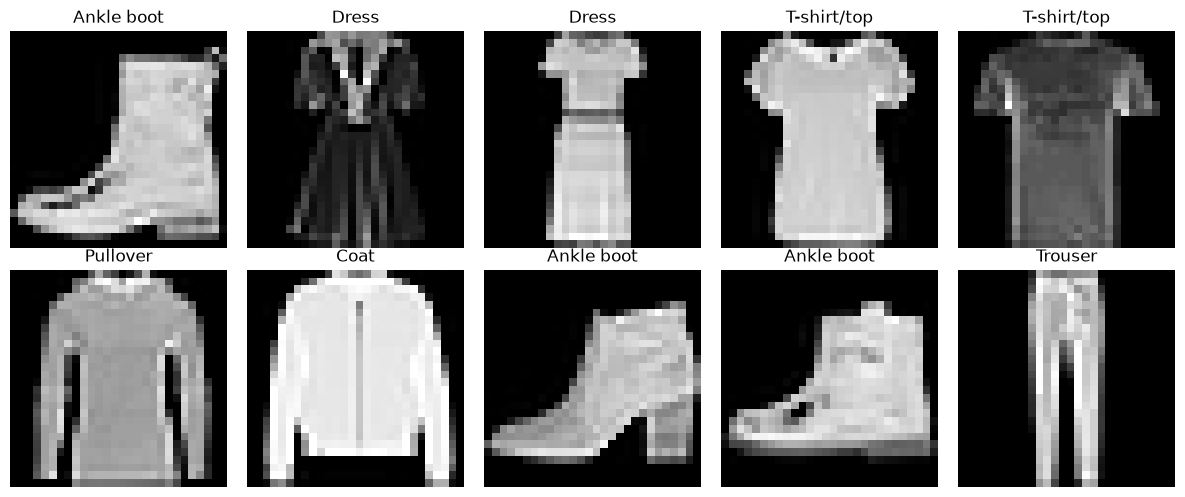

In [20]:
# HIỂN THỊ MỘT SỐ ẢNH MẪU 
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

images, labels = next(iter(DataLoader(
    train_dataset, batch_size=10, shuffle=True
)))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [21]:
# Kích thước mỗi batch
batch_size = 64 # mô hình xử lý 64 ảnh trong mỗi batch.

# Tạo DataLoader cho tập huấn luyện
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True #xáo trộn dữ liệu huấn luyện ở mỗi epoch.
)

# Tạo DataLoader cho tập kiểm tra
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False # giữ nguyên thứ tự dữ liệu kiểm tra.
)

# Kiểm tra một batch dữ liệu
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Pixel minimum:", images.min().item())
print("Pixel maximum:", images.max().item())

Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])
Pixel minimum: 0.0
Pixel maximum: 1.0


## BƯỚC 2. Xây dựng Neural Network

In [22]:
# Chọn thiết bị huấn luyện
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Xây dựng mô hình ANN
class FashionMNISTModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

# Khởi tạo mô hình
model = FashionMNISTModel().to(device)

print(model)
print("Device:", device)

FashionMNISTModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Device: cpu


In [23]:
# Kiểm tra mô hình với một batch
images, labels = next(iter(train_loader))
images = images.to(device)
outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Number of classes:", outputs.shape[1])

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
Number of classes: 10


# BƯỚC 3. VÒNG LẶP HUẤN LUYỆN

* Thiết lập hàm mất mát và bộ tối ưu hóa (Loss Function & Optimizer).

dùng để thiết lập hàm mất mát CrossEntropyLoss và bộ tối ưu Adam nhằm đánh giá sai lệch dự đoán, cập nhật trọng số và giúp mô hình giảm Loss trong quá trình huấn luyện.

In [24]:
# Hàm mất mát dùng cho bài toán phân loại nhiều lớp
loss_fn = nn.CrossEntropyLoss() # đo mức độ sai lệch giữa dự đoán của mô hình và nhãn thật.

# Bộ tối ưu cập nhật trọng số của mô hình
optimizer = torch.optim.Adam( # cập nhật trọng số để giảm loss.
    model.parameters(),
    lr=0.001 # learning rate, quyết định độ lớn mỗi bước cập nhật trọng số.
)

print("Loss function:", loss_fn)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


* MODEL TRAINING - ONE EPOCH

Công dụng: Đưa dữ liệu vào mô hình để dự đoán, tính Loss, thực hiện lan truyền ngược (Backpropagation) và cập nhật trọng số bằng Adam nhằm giảm sai số. Cuối cùng, tính Loss trung bình và Accuracy của mô hình trong Epoch đó.

In [25]:
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Forward pass: dự đoán
        outputs = model(images)

        # 2. Tính loss
        loss = loss_fn(outputs, labels)

        # 3. Xóa gradient cũ
        optimizer.zero_grad()

        # 4. Backpropagation: tính gradient
        loss.backward()

        # 5. Cập nhật trọng số
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

* Xây dựng hàm đánh giá mô hình (Model Evaluation).

Đánh giá hiệu suất của mô hình trên tập dữ liệu bằng cách tính Loss trung bình (Average Loss) và độ chính xác (Accuracy), không cập nhật trọng số của mô hình.

In [26]:
def evaluate(model, data_loader, loss_fn, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            total_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

* Huấn luyện mô hình và theo dõi Loss, Accuracy trên tập Train và Test

Thực hiện huấn luyện mô hình trong 5 Epoch, đánh giá hiệu suất sau mỗi Epoch và lưu lại các chỉ số để theo dõi quá trình học.

In [28]:
num_epochs = 5

train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )

    test_loss, test_acc = evaluate(
        model, test_loader, loss_fn, device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    test_losses.append(test_loss)
    test_accuracies.append(test_acc)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2%} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_acc:.2%}"
    )

Epoch [1/5] | Train Loss: 0.2940 | Train Accuracy: 89.15% | Test Loss: 0.3500 | Test Accuracy: 87.33%
Epoch [2/5] | Train Loss: 0.2807 | Train Accuracy: 89.56% | Test Loss: 0.3695 | Test Accuracy: 86.27%
Epoch [3/5] | Train Loss: 0.2706 | Train Accuracy: 89.97% | Test Loss: 0.3382 | Test Accuracy: 87.79%
Epoch [4/5] | Train Loss: 0.2583 | Train Accuracy: 90.39% | Test Loss: 0.3548 | Test Accuracy: 87.40%
Epoch [5/5] | Train Loss: 0.2471 | Train Accuracy: 90.70% | Test Loss: 0.3256 | Test Accuracy: 88.33%


* BẢN ĐỒ LOSS

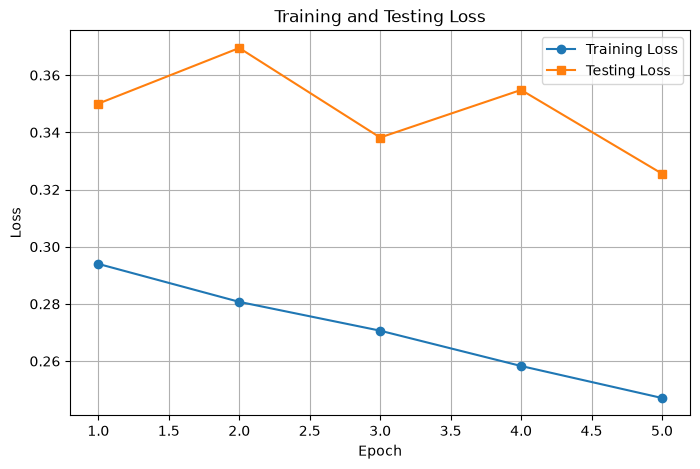

In [45]:

plt.figure(figsize=(8, 5))

plt.plot(range(1, num_epochs + 1), train_losses, marker="o",
         label="Training Loss")
plt.plot(range(1, num_epochs + 1), test_losses, marker="s",
         label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Testing Loss")
plt.legend()
plt.grid(True)
plt.savefig("results/loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## BƯỚC 4: ĐÁNH GIÁ ĐỘ CHÍNH XÁC

In [29]:
test_loss, test_accuracy = evaluate(
    model, test_loader, loss_fn, device
)

print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy:.2%}")

Final Test Loss: 0.3256
Final Test Accuracy: 88.33%


* Accuracy, Precision, Recall, F1-score, Confusion Matrix

Accuracy:        88.33%
Macro Precision: 88.34%
Macro Recall:    88.33%
Macro F1-score:  88.16%

Metrics by class:
T-shirt/top  | Precision: 78.12% | Recall: 90.00% | F1-score: 83.64%
Trouser      | Precision: 98.19% | Recall: 97.60% | F1-score: 97.89%
Pullover     | Precision: 80.28% | Recall: 79.80% | F1-score: 80.04%
Dress        | Precision: 89.83% | Recall: 88.30% | F1-score: 89.06%
Coat         | Precision: 77.07% | Recall: 84.70% | F1-score: 80.71%
Sandal       | Precision: 97.55% | Recall: 95.60% | F1-score: 96.57%
Shirt        | Precision: 76.30% | Recall: 58.90% | F1-score: 66.48%
Sneaker      | Precision: 92.27% | Recall: 96.70% | F1-score: 94.43%
Bag          | Precision: 97.02% | Recall: 97.70% | F1-score: 97.36%
Ankle boot   | Precision: 96.81% | Recall: 94.00% | F1-score: 95.38%


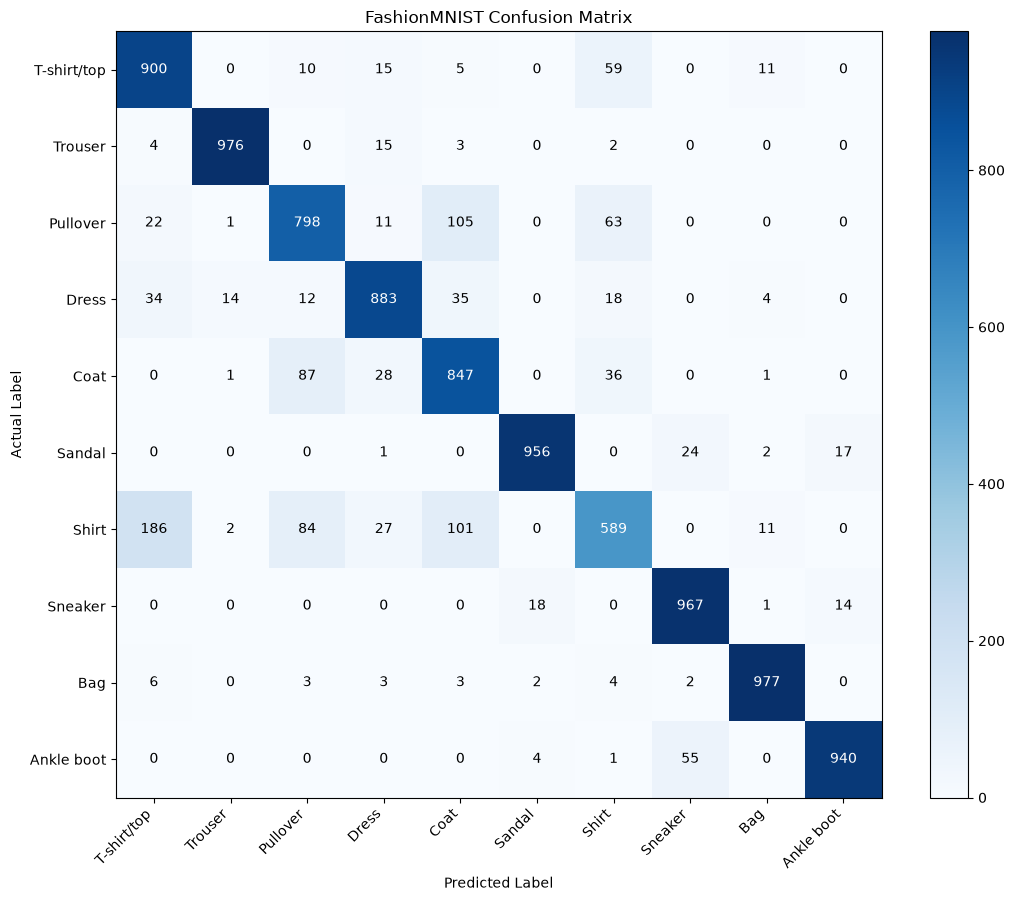

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import torch

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# 1. Thu thập nhãn thực tế và nhãn dự đoán
model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# 2. Tính Confusion Matrix
num_classes = 10
cm = np.zeros((num_classes, num_classes), dtype=int)

for true_label, pred_label in zip(y_true, y_pred):
    cm[true_label, pred_label] += 1

# 3. Tính Accuracy, Precision, Recall và F1-score
tp = np.diag(cm)

precision = tp / np.maximum(cm.sum(axis=0), 1)
recall = tp / np.maximum(cm.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(
    precision + recall, 1e-12
)

accuracy = np.mean(y_true == y_pred)

print(f"Accuracy:        {accuracy:.2%}")
print(f"Macro Precision: {precision.mean():.2%}")
print(f"Macro Recall:    {recall.mean():.2%}")
print(f"Macro F1-score:  {f1.mean():.2%}")

print("\nMetrics by class:")
for i, name in enumerate(class_names):
    print(
        f"{name:12s} | "
        f"Precision: {precision[i]:.2%} | "
        f"Recall: {recall[i]:.2%} | "
        f"F1-score: {f1[i]:.2%}"
    )

# 4. Vẽ Confusion Matrix
plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("FashionMNIST Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

* Ảnh dự đoán

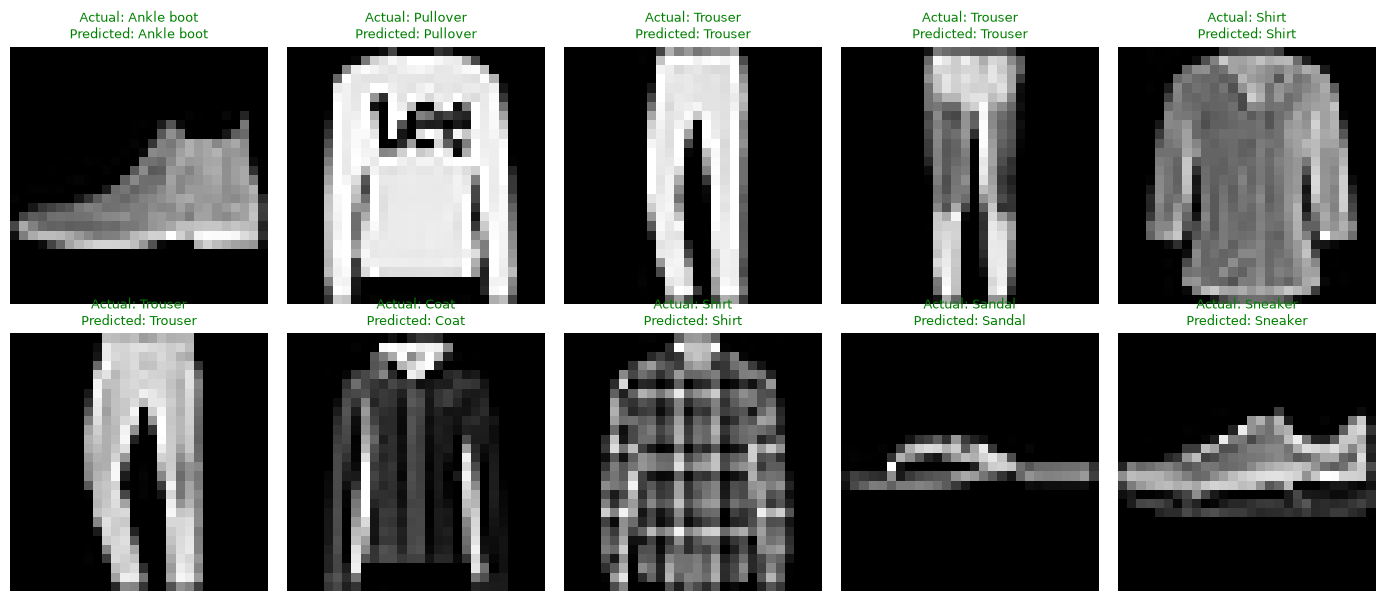

In [35]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

model.eval()

images, labels = next(iter(test_loader))
images_device = images.to(device)

with torch.no_grad():
    outputs = model(images_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    color = "green" if actual == predicted else "red"
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
Path("results").mkdir(parents=True, exist_ok=True)
plt.savefig("results/predictions.png", dpi=200, bbox_inches="tight")
plt.show()

## BƯỚC 5: LƯU VÀ TẢI MÔ HÌNH

In [34]:
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "fashion_mnist_ann.pth"

torch.save(model.state_dict(), model_path)

print("Model saved to:", model_path)

Model saved to: models\fashion_mnist_ann.pth


In [47]:
# Khởi tạo mô hình mới
loaded_model = FashionMNISTModel().to(device)

# Tải trọng số đã lưu
loaded_model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

# Chuyển sang chế độ đánh giá
loaded_model.eval()

print("Model loaded successfully!")

# Kiểm tra mô hình sau khi tải
test_loss_loaded, test_accuracy_loaded = evaluate(
    loaded_model,
    test_loader,
    loss_fn,
    device
)

print(f"Loaded Model Test Loss: {test_loss_loaded:.4f}")
print(f"Loaded Model Test Accuracy: {test_accuracy_loaded:.2%}")

Model loaded successfully!
Loaded Model Test Loss: 0.3256
Loaded Model Test Accuracy: 88.33%
